# Week 2: Does the model react the way it should?

See `week2/README.md` for the task. This notebook works through the sections in order.

## Setup

Same as week 1: move from `week2/` up to `Project3/`, so `import src` and the `data/...` paths work.

In [12]:
import os
import sys
from pathlib import Path

if Path.cwd().name == "week2":  # only move up once, even if this cell is re-run
    os.chdir("..")
sys.path.insert(0, ".")  # make `src` importable

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.data import binary_label, study_table, usable_findings
from src.embeddings import embedding_path, load_embeddings

## 1. Classifier

Week 1 used 5-fold cross-validation, so there was no single trained probe. Here we train **one** probe and freeze it, so every edit is judged by the same classifier.

- Studies: clear pleural effusion label (positive/negative) and a usable Findings text.
- Split once by patient: 70% training, 30% held-out. All edits are later applied to the held-out reports only.

In [13]:
studies = study_table()
X = load_embeddings(embedding_path("findings"), studies)

label = binary_label(studies, "pleural_effusion")
keep = (usable_findings(studies) & label.notna()).to_numpy()
data = studies[keep].reset_index(drop=True)  # only the clear effusion studies
X_eff = X[keep]
y = label[keep].to_numpy().astype(int)

split = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=0)
train, test = next(split.split(X_eff, y, groups=data["patient_id"]))
print("training:", len(train), " held-out:", len(test))

training: 554  held-out: 230


Train the probe on the training part only, then check it on the held-out part. It should be close to week 1 (about 0.91).

In [14]:
probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
probe.fit(X_eff[train], y[train])  # from here on: frozen, never fitted again

p_test = probe.predict_proba(X_eff[test])[:, 1]
print("held-out AUROC:", round(roc_auc_score(y[test], p_test), 3))

held-out AUROC: 0.916


**Questions on section 1**

- *Why train once and freeze?* So every edit is judged by the **same** classifier. With cross-validation there would be 5 different probes, and a change in prediction could come from the probe instead of from the edit.
- *Why edit only the held-out reports?* The probe has already seen the training reports and may partly remember them. Held-out reports show how it behaves on new text, as it would in use.

## 2. Interventions

`src/edits.py` (mentioned in the README) is not in our project, so two small helpers are defined here: `sentences` splits a report into sentences, `mentions_effusion` finds the effusion sentences.

In [15]:
import re

import matplotlib.pyplot as plt
import pandas as pd

from src.embeddings import embed_texts, load_encoder


def sentences(text):
    """Split a report into sentences at '.', '!' or '?' followed by a space."""
    return re.split(r"(?<=[.!?])\s+", text.strip())


def mentions_effusion(sentence):
    return "effusion" in sentence.lower()


def replace_words(text, mapping):
    """Replace whole words using `mapping` (lowercase keys), keeping a capital first letter."""
    def repl(m):
        new = mapping[m.group().lower()]
        return new.capitalize() if m.group()[0].isupper() else new
    return re.sub(r"\b(" + "|".join(mapping) + r")\b", repl, text, flags=re.IGNORECASE)

Five edits, with the hypothesis written down **before** running them:

| Edit | Applied to (held-out) | Hypothesis | Why |
|---|---|---|---|
| negate: effusion sentence → "No pleural effusion." | reports with effusion | **drops** | the text now says there is no effusion |
| delete the effusion sentence | reports with effusion | **drops, but less than negate** | the effusion is gone, but there is no explicit "no", and neighbouring findings (atelectasis, blunted angles) still hint at effusion |
| swap left ↔ right | reports with effusion and "left"/"right" | **stays the same** | the side changes, not the presence |
| change size (small ↔ large, trace → large, ...) | reports with effusion and a size word | **stays the same** | the size changes, not the presence |
| insert "There is a small left pleural effusion." | reports without effusion | **increases** | the text now describes an effusion |

An edit only counts for a report if it actually changes the text.

In [16]:
def negate(text):
    """Replace the first effusion sentence by 'No pleural effusion.' and drop any other effusion sentences."""
    sents = sentences(text)
    hits = [i for i, s in enumerate(sents) if mentions_effusion(s)]
    if not hits:
        return None
    kept = ["No pleural effusion." if i == hits[0] else s for i, s in enumerate(sents) if i not in hits[1:]]
    return " ".join(kept)


def delete_sentence(text):
    """Remove every sentence that mentions an effusion; the rest of the report stays."""
    sents = sentences(text)
    kept = [s for s in sents if not mentions_effusion(s)]
    return " ".join(kept) if len(kept) < len(sents) else None


def swap_sides(text):
    """Exchange every 'left' and 'right'."""
    return replace_words(text, {"left": "right", "right": "left"})


SIZES = {"trace": "large", "tiny": "large", "small": "large", "moderate": "small", "large": "small"}


def change_size(text):
    """Change the size word in the effusion sentences (small <-> large, ...)."""
    return " ".join(replace_words(s, SIZES) if mentions_effusion(s) else s for s in sentences(text))


def insert_effusion(text):
    """Append an effusion sentence."""
    return text + " There is a small left pleural effusion."


# name: (edit function, applied to held-out reports that are ..., hypothesis)
EDITS = {
    "negate": (negate, "positive", "drops"),
    "delete effusion sentence": (delete_sentence, "positive", "drops"),
    "swap left/right": (swap_sides, "positive", "same"),
    "change size": (change_size, "positive", "same"),
    "insert effusion": (insert_effusion, "negative", "increases"),
}

In [17]:
held = data.iloc[test].reset_index(drop=True)  # held-out studies
X_held = X_eff[test]
y_held = y[test]
p_held = probe.predict_proba(X_held)[:, 1]
texts_held = held["findings"].tolist()

edited = {}  # edit name -> DataFrame with one row per report the edit applies to
for name, (edit, applies_to, hypothesis) in EDITS.items():
    rows = []
    for i, text in enumerate(texts_held):
        if y_held[i] != (applies_to == "positive"):
            continue
        new = edit(text)
        if new is not None and new != text:  # only reports the edit actually changes
            rows.append({"report": i, "original": text, "edited": new})
    edited[name] = pd.DataFrame(rows)
    print(f"{name:25s} applies to {len(rows)} reports")

negate                    applies to 173 reports
delete effusion sentence  applies to 173 reports
swap left/right           applies to 161 reports
change size               applies to 120 reports
insert effusion           applies to 41 reports


Read one example per edit, to check the edit does what we intended:

In [18]:
for name, df in edited.items():
    print(f"=== {name} ===")
    print("BEFORE:", df["original"].iloc[0])
    print("AFTER: ", df["edited"].iloc[0], "\n")

=== negate ===
BEFORE: The patient has a small left pleural effusion with basilar atelectasis. No pneumothorax is identified. Mild right basilar atelectasis is noted. The left lung is clear. Heart size is normal. Fractures are seen of the left sixth, seventh, eighth and tenth ribs. There may be a ninth rib fracture which is obscured by soft tissue structures.
AFTER:  No pleural effusion. No pneumothorax is identified. Mild right basilar atelectasis is noted. The left lung is clear. Heart size is normal. Fractures are seen of the left sixth, seventh, eighth and tenth ribs. There may be a ninth rib fracture which is obscured by soft tissue structures. 

=== delete effusion sentence ===
BEFORE: The patient has a small left pleural effusion with basilar atelectasis. No pneumothorax is identified. Mild right basilar atelectasis is noted. The left lung is clear. Heart size is normal. Fractures are seen of the left sixth, seventh, eighth and tenth ribs. There may be a ninth rib fracture which

The examples look as intended. Two things to note:
- Some reports labelled *positive* never use the word "effusion" (e.g. "blunting of both costophrenic angles"), so negate/delete only apply to 173 of the positive held-out reports.
- Many *negative* reports already say "No pleural effusion", so after the insert edit they contradict themselves ("No associated pleural effusion. ... There is a small left pleural effusion.").

## 3. Measurements

For each edit: embed the edited reports with the same frozen BioClinicalBERT, score them with the frozen probe, and compare with the original report:
- **mean p before / after**: mean probability of effusion
- **flip rate**: share of reports whose decision (p ≥ 0.5 or not) changed
- **cosine shift**: 1 − cosine similarity between original and edited embedding (0 = identical direction)

This cell takes about a minute (it runs BERT on ~670 edited reports).

In [19]:
tokenizer, model = load_encoder()


def cosine_distance(A, B):
    """1 - cosine similarity, row by row."""
    return 1 - (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1))


for name, df in edited.items():
    X_new = embed_texts(df["edited"].tolist(), tokenizer, model, verbose=False)
    X_old = X_held[df["report"]]
    df["p_before"] = p_held[df["report"]]
    df["p_after"] = probe.predict_proba(X_new)[:, 1]
    df["flipped"] = (df["p_before"] >= 0.5) != (df["p_after"] >= 0.5)
    df["cosine_shift"] = cosine_distance(X_old, X_new)
    df["X_new"] = list(X_new)  # keep the edited embeddings for the UMAP in section 4

table = pd.DataFrame([
    {
        "edit": name,
        "hypothesis": EDITS[name][2],
        "n reports": len(df),
        "mean p before": df["p_before"].mean(),
        "mean p after": df["p_after"].mean(),
        "flip rate": df["flipped"].mean(),
        "mean cosine shift": df["cosine_shift"].mean(),
    }
    for name, df in edited.items()
]).round(4)
table

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4073.19it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,edit,hypothesis,n reports,mean p before,mean p after,flip rate,mean cosine shift
0,negate,drops,173,0.9522,0.4736,0.4855,0.0089
1,delete effusion sentence,drops,173,0.9522,0.6723,0.3064,0.0141
2,swap left/right,same,161,0.9362,0.9368,0.0124,0.0004
3,change size,same,120,0.9547,0.9544,0.0000,0.0004
4,insert effusion,increases,41,0.3412,0.6625,0.3415,0.0062


**Results (for the poster)**

- **Negation lowers the probability a lot, but flips only half the decisions.** Mean probability drops from 0.95 to 0.47, yet for about half the reports the probe still says "effusion" after the text says *"No pleural effusion."* The rest of the report (atelectasis, opacities, the word "effusion" itself) keeps the prediction up.
- **Deleting the sentence has a smaller effect than negating it** (0.95 → 0.67, 31% flips), as hypothesised: without an explicit "no", the neighbouring findings that usually come with effusion still push the prediction towards effusion.
- **Side and size are ignored, as they should be:** swapping left/right or changing the size word changes almost nothing (≤ 1.2% flips, cosine shift 0.0004).
- **Inserting an effusion raises the probability** (0.34 → 0.66, 34% flips), but many reports stay "no effusion", partly because they still contain "No pleural effusion" and now contradict themselves.

## 4. Visualization

**Figure 1:** mean probability before (open circle) and after (filled circle) each edit, coloured by hypothesis (red = should drop, grey = should stay, green = should increase). The dashed line is the decision threshold 0.5.

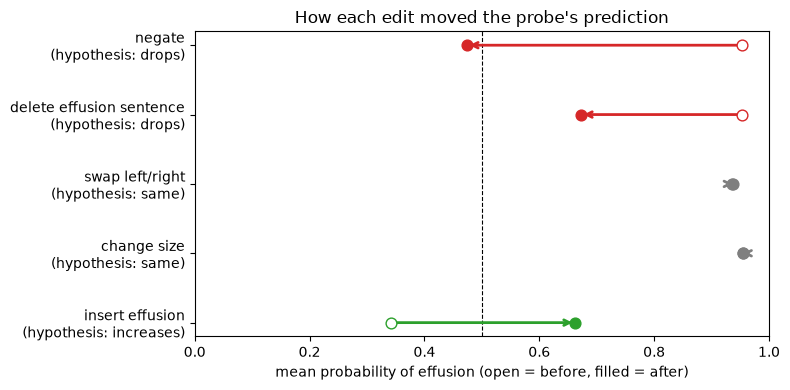

In [20]:
colours = {"drops": "tab:red", "same": "tab:grey", "increases": "tab:green"}

fig, ax = plt.subplots(figsize=(8, 4))
for row, (before, after, hypothesis) in enumerate(zip(table["mean p before"], table["mean p after"], table["hypothesis"])):
    c = colours[hypothesis]
    ax.annotate("", xy=(after, row), xytext=(before, row), arrowprops=dict(arrowstyle="->", color=c, lw=2))
    ax.scatter(before, row, color="white", edgecolor=c, s=60, zorder=3)  # before: open circle
    ax.scatter(after, row, color=c, s=60, zorder=3)                      # after: filled circle
ax.axvline(0.5, color="black", lw=0.8, ls="--")
ax.set_yticks(range(len(table)), [f"{e}\n(hypothesis: {h})" for e, h in zip(table["edit"], table["hypothesis"])])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("mean probability of effusion (open = before, filled = after)")
ax.set_title("How each edit moved the probe's prediction")
plt.tight_layout()
plt.show()

All arrows point the way we hypothesised. The "drop" edits do not cross far below 0.5 on average, which is why only part of the decisions flip.

**Figure 2.** Left: UMAP fitted on the **original** embeddings only; edited reports are then placed into that same map (`transform`). Four example reports (stars) and where each edit moved them; a filled end means the decision flipped. Right: the cosine shift of every edited held-out report, black = decision flipped.

Takes about 30 seconds.

/Users/KAROLINE/Desktop/RAI/Project3/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


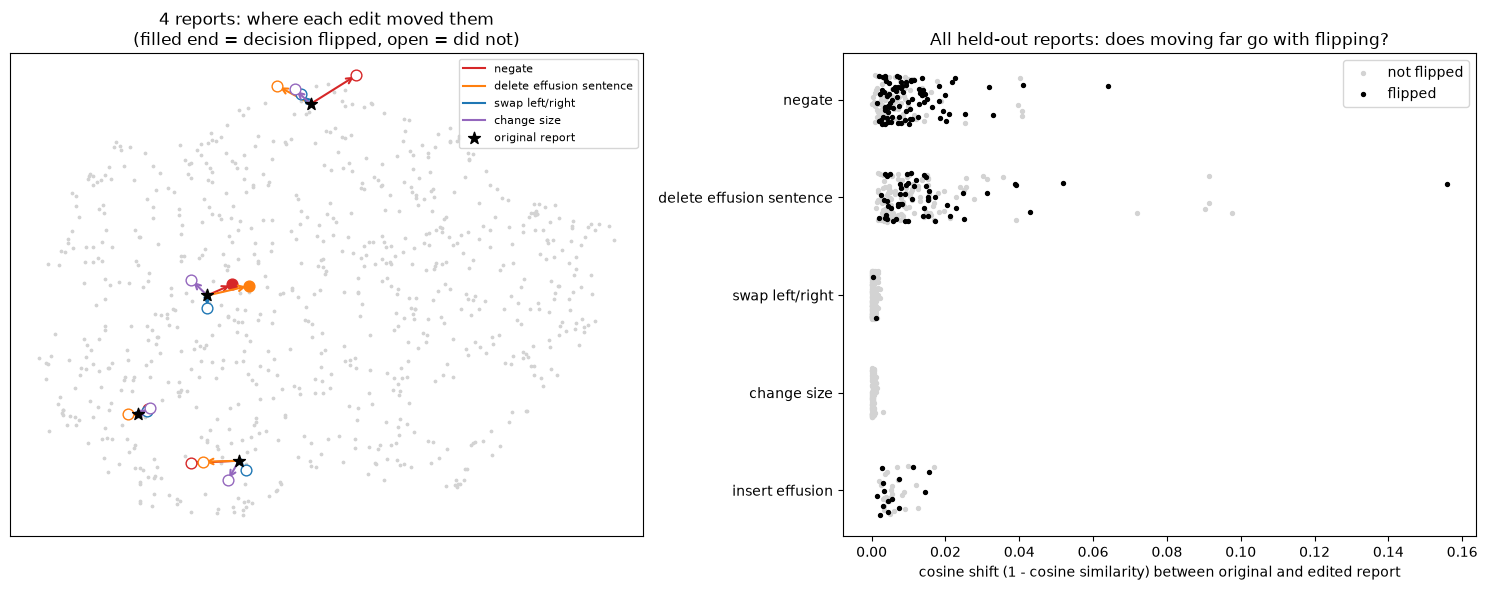

In [21]:
import umap

reducer = umap.UMAP(n_neighbors=15, random_state=0).fit(X_eff)  # fit on ORIGINAL embeddings only
xy_all = reducer.embedding_
xy_held = xy_all[test]

# a few positive reports that every 'positive' edit applies to
positive_edits = [n for n in EDITS if EDITS[n][1] == "positive"]
common = set.intersection(*(set(edited[n]["report"]) for n in positive_edits))
examples = sorted(common)[:4]

edit_colours = {"negate": "tab:red", "delete effusion sentence": "tab:orange",
                "swap left/right": "tab:blue", "change size": "tab:purple"}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
ax.scatter(*xy_all.T, s=3, c="lightgrey")
for name in positive_edits:
    df = edited[name].set_index("report").loc[examples]
    xy_new = reducer.transform(np.vstack(df["X_new"]))
    for (x0, y0), (x1, y1), flipped in zip(xy_held[examples], xy_new, df["flipped"]):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="->", color=edit_colours[name], lw=1.5))
        ax.scatter(x1, y1, s=60, color=edit_colours[name] if flipped else "white",
                   edgecolor=edit_colours[name], zorder=3)
    ax.plot([], [], color=edit_colours[name], label=name)
ax.scatter(*xy_held[examples].T, s=80, c="black", marker="*", zorder=4, label="original report")
ax.legend(fontsize=8)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("4 reports: where each edit moved them\n(filled end = decision flipped, open = did not)")

ax = axes[1]
for row, name in enumerate(EDITS):
    df = edited[name]
    jitter = np.random.default_rng(0).uniform(-0.25, 0.25, len(df))
    ax.scatter(df["cosine_shift"][~df["flipped"]], row + jitter[~df["flipped"]], s=8, c="lightgrey", label="not flipped" if row == 0 else None)
    ax.scatter(df["cosine_shift"][df["flipped"]], row + jitter[df["flipped"]], s=8, c="black", label="flipped" if row == 0 else None)
ax.set_yticks(range(len(EDITS)), list(EDITS))
ax.invert_yaxis()
ax.set_xlabel("cosine shift (1 - cosine similarity) between original and edited report")
ax.set_title("All held-out reports: does moving far go with flipping?")
ax.legend()
plt.tight_layout()
plt.show()

**Results (for the poster)**

- **Moving far does not mean flipping.** Within negate, flipped reports move somewhat more on average (0.011 vs 0.007), but the two groups overlap heavily: many reports move far without flipping, others flip after a tiny move. For insert, flipped and not-flipped reports moved exactly as far on average (0.006). Across edits, delete moves the representation *more* than negate on average (0.014 vs 0.009) but flips *fewer* decisions (31% vs 49%).
- **Why:** cosine distance measures how much the *whole* text changed, mostly how many words were removed or replaced. The probe only looks along one direction in the 768-dimensional space (its weights). A large move in other directions does not matter; a small move along the probe's direction can flip the decision.
- **All shifts are small numbers** (mostly below 0.02), because BioClinicalBERT's mean-pooled vectors of different reports already point in very similar directions: two random reports have a cosine similarity of 0.95 on average. So cosine distance is a poor measure of *clinically relevant* change.
- **Careful with the UMAP picture:** placing new points into an existing UMAP is approximate, so even the near-zero edits (swap, size) can look like visible moves on the left.

## 5. Interpretation

- **Were the hypotheses confirmed?** In direction, yes: negate and delete lowered the probability, insert raised it, swap and size changed nothing. In size, only partly: half the negated reports were still predicted as effusion.
- **Why not fully?** The probe does not read the effusion sentence like a radiologist. It reacts to the overall content of the report, and findings that usually come with effusion (atelectasis, opacities, blunted angles) stay in the text. Mean pooling also mixes the one changed sentence with all the unchanged ones.
- **Flip rate vs cosine shift:** they do not match. Delete moved the representation more but flipped less than negate, and within an edit the cosine shift of flipped and not-flipped reports overlaps heavily. Cosine distance tells you *that* the text changed, not *whether the change matters* for the question asked.

## Extra: TF-IDF

Same edits, but with a TF-IDF probe. The vectoriser is fitted once on the original training reports; edited reports are only transformed.

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

texts_eff = data["findings"].to_numpy()
tfidf_probe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=1000))
tfidf_probe.fit(texts_eff[train], y[train])  # vocabulary from the original training reports only
print("TF-IDF held-out AUROC:", round(roc_auc_score(y[test], tfidf_probe.predict_proba(texts_eff[test])[:, 1]), 3))

rows = []
for name, df in edited.items():
    before = tfidf_probe.predict_proba(df["original"])[:, 1]
    after = tfidf_probe.predict_proba(df["edited"])[:, 1]
    rows.append({
        "edit": name,
        "hypothesis": EDITS[name][2],
        "TF-IDF p before": before.mean(),
        "TF-IDF p after": after.mean(),
        "TF-IDF flip rate": ((before >= 0.5) != (after >= 0.5)).mean(),
        "BERT flip rate": df["flipped"].mean(),
    })
pd.DataFrame(rows).round(3)

TF-IDF held-out AUROC: 0.891


,edit,hypothesis,TF-IDF p before,TF-IDF p after,TF-IDF flip rate,BERT flip rate
0,negate,drops,0.854,0.769,0.006,0.486
1,delete effusion sentence,drops,0.854,0.809,0.000,0.306
2,swap left/right,same,0.852,0.852,0.000,0.012
3,change size,same,0.853,0.840,0.000,0.000
4,insert effusion,increases,0.678,0.733,0.073,0.341


**Results (for the poster)**

- **TF-IDF hardly reacts to any edit:** at most 7% flips, even for negation (under 1%). Its probabilities move a little in the right direction, but almost never across 0.5.
- **Why:** TF-IDF counts words. *"No pleural effusion."* still contains "pleural" and "effusion", and the rest of the report is unchanged, so the word counts barely move. BioClinicalBERT reads words in context, so "no" changes the meaning of the sentence.
- **Lesson:** in week 1 TF-IDF had a slightly *higher* AUROC than BERT, but here it is much worse at reacting to negation. A high score on the test set does not show that a model reacts to the right things; controlled edits do.